In [1]:
import sys
import os
import pickle
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
# read_ids = list(range(0, 8+1))
read_ids = [2]
plot_id = 2

In [4]:
# read
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_datas(path, read_ids,
									  with_whisking=True)

# # clear nan values
# for i in range(len(file_ids)):
# 	# mask = motion_pcs[i][0].notna().all(axis=1)
# 	mask = continuous_behaviors[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	motion_pcs[i][0] = motion_pcs[i][0][mask]
# 	motion_pcs[i][1] = motion_pcs[i][1][mask]
# 	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
plot_idx = file_ids.index(plot_id)

# states = [ds[selection_bhl] for ds in states]

In [6]:
print(traces[plot_idx].shape)

(10301, 9392)


0.0


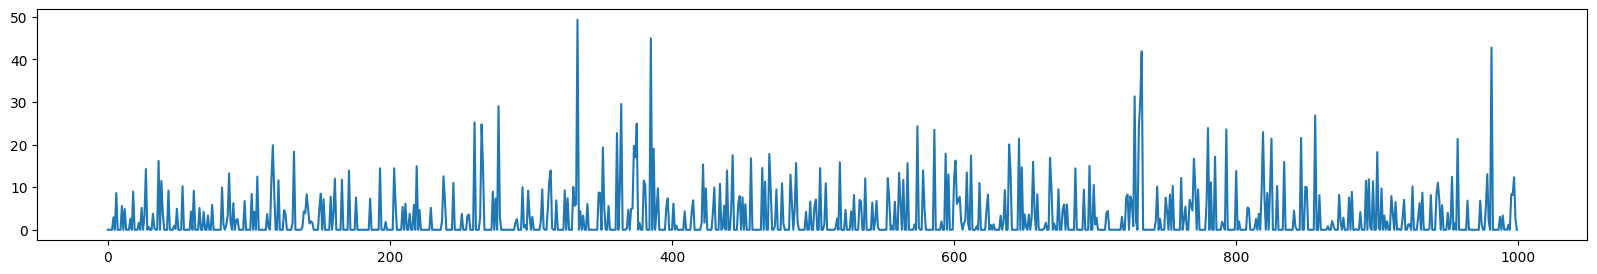

In [7]:
plt.figure(figsize=(20, 3))
plt.plot(traces[plot_idx].values[:1000, 0])

print(np.median(traces[plot_idx]))

In [8]:
# prep

def reconstruct_calcium(spikes, fs, decay=2.0):
	dt = 1.0 / fs
	gamma = np.exp(-dt / decay)
	trace = np.zeros(spikes.shape, dtype=np.float32)
	for t in range(1, spikes.shape[0]):
		trace[t, :] = gamma * trace[t-1, :] + spikes[t, :]
	return trace

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces_deconvolved = [pd.DataFrame(reconstruct_calcium(trace.values, fs=sr), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

67.94672


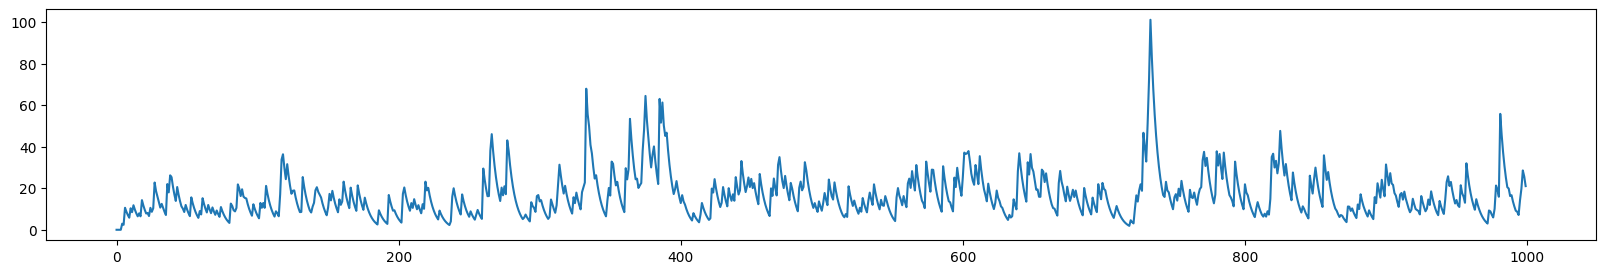

In [9]:
plt.figure(figsize=(20, 3))
plt.plot(traces_deconvolved[plot_idx].values[:1000, 0])

print(np.median(traces_deconvolved[plot_idx].values))